# Student C — JPEG Baseline Evaluation on the Kodak Dataset

## Purpose

This notebook establishes a conventional JPEG baseline for the image-compression project. It compresses the 24 Kodak test images at several JPEG quality settings, measures the resulting bit rate and reconstruction quality, benchmarks decoding, and exports tables and plots for comparison with learned image codecs.

## Evaluation workflow

1. Install the Python packages used by the notebook.
2. Download the 24 Kodak PNG images and verify that the files are valid.
3. Inspect the image count, dimensions, and color mode.
4. define and sanity-check the evaluation metrics: bpp, PSNR, and MS-SSIM.
5. Run a one-image JPEG smoke test at five quality settings.
6. Evaluate all 24 images, save per-image and averaged results, and generate rate–distortion plots.
7. Package the generated results into a ZIP archive.

## Important interpretation
- **bpp** is calculated from the actual compressed JPEG file size: `8 × file_size_bytes / (width × height)`.
- **PSNR** is reported in decibels (dB); higher is better. Identical images produce infinite PSNR.
- **MS-SSIM** is a perceptual similarity measure; values closer to 1 indicate greater similarity.
- **Decode time** in this notebook is the median of repeated in-memory Pillow decode measurements. File reading from disk is excluded from the timed section. It is therefore a practical software measurement, not a hardware-independent codec complexity metric.

## Execution notes

Run the cells from top to bottom in a fresh Google Colab runtime. The dataset is stored under `/content/kodak`, and generated results are stored under `/content/jpeg_evaluation`. These paths are temporary runtime storage; download the ZIP before the Colab session ends if you need to keep the outputs.


## 1. Install the required packages

This cell installs the libraries used in the rest of the notebook.

- **Pillow (`PIL`)** reads PNG files, writes JPEG files, and decodes the compressed JPEGs.
- **NumPy** provides numerical arrays and median calculations.
- **pandas** stores per-image measurements in tables and writes CSV files.
- **Matplotlib** creates the rate–distortion plots.
- **scikit-image** provides the PSNR implementation.
- **pytorch-msssim** provides the MS-SSIM implementation.

The `-q` flag makes pip quieter. In Colab, installation may take a little time. If a package was already installed, pip may report that it is satisfied. After changing package versions, a runtime restart may sometimes be required.

In [5]:
!pip -q install pillow numpy pandas matplotlib scikit-image pytorch-msssim

## 2. Download and validate the Kodak test images

The Kodak dataset is used here as a fixed image set for evaluating compression methods. The loop downloads `kodim01.png` through `kodim24.png` into `/content/kodak`.

### What the code does

1. `Path` constructs filesystem paths, and `mkdir(..., exist_ok=True)` creates the destination folder if needed.
2. The URL is built from a base address and a zero-padded filename. For example, image 1 becomes `kodim01.png`.
3. `urllib.request.Request` supplies a browser-like User-Agent header. This can avoid servers rejecting a default Python request.
4. `urlopen` downloads the bytes. `BytesIO` exposes those bytes as a file-like object in memory.
5. `PIL.Image.verify()` checks that the downloaded data is a valid image. Only verified bytes are written to disk.
6. Successful and failed filenames are collected separately, then a final check counts the PNG files.

### Expected result and checks

The final count should be **24**. If fewer than 24 files are present, do not continue to the benchmark: fix the download failures first. The folder is in Colab's temporary `/content` storage

In [6]:

import urllib.request
from pathlib import Path
from io import BytesIO
from PIL import Image

dataset_dir = Path("/content/kodak")
dataset_dir.mkdir(parents=True, exist_ok=True)
# Notice the extra /kodak/ in the URL
base_url = "https://r0k.us/graphics/kodak/kodak/"

downloaded = []
failed = []

for i in range(1, 25):
    filename = f"kodim{i:02d}.png"
    url = base_url + filename
    output_path = dataset_dir / filename

    try:
        request = urllib.request.Request(
            url,
            headers={"User-Agent": "Mozilla/5.0"}
        )

        with urllib.request.urlopen(request, timeout=30) as response:
            image_bytes = response.read()

        # Verify the downloaded file is a valid image
        with Image.open(BytesIO(image_bytes)) as image:
            image.verify()

        # Save only after successful verification
        output_path.write_bytes(image_bytes)
        downloaded.append(filename)
        print(f"Downloaded: {filename}")

    except Exception as error:
        failed.append(filename)
        print(f"Failed: {filename} — {error}")

print("\n========== SUMMARY ==========")
print(f"Successfully downloaded: {len(downloaded)}/24")
print(f"Failed: {len(failed)}")

if failed:
    print("Failed files:", failed)

# Check the final dataset
images = sorted(dataset_dir.glob("kodim*.png"))
print(f"PNG files in dataset folder: {len(images)}")

if len(images) == 24:
    print("Dataset is ready for evaluation!")

Downloaded: kodim01.png
Downloaded: kodim02.png
Downloaded: kodim03.png
Downloaded: kodim04.png
Downloaded: kodim05.png
Downloaded: kodim06.png
Downloaded: kodim07.png
Downloaded: kodim08.png
Downloaded: kodim09.png
Downloaded: kodim10.png
Downloaded: kodim11.png
Downloaded: kodim12.png
Downloaded: kodim13.png
Downloaded: kodim14.png
Downloaded: kodim15.png
Downloaded: kodim16.png
Downloaded: kodim17.png
Downloaded: kodim18.png
Downloaded: kodim19.png
Downloaded: kodim20.png
Downloaded: kodim21.png
Downloaded: kodim22.png
Downloaded: kodim23.png
Downloaded: kodim24.png

========== SUMMARY ==========
Successfully downloaded: 24/24
Failed: 0
PNG files in dataset folder: 24
Dataset is ready for evaluation!


## 3. Inspect the dataset

This cell confirms that the expected images are present and prints basic metadata for the first three files.

- `glob("kodim*.png")` finds files matching the Kodak filename pattern.
- `sorted(...)` gives a stable order (`kodim01`, `kodim02`, …).
- `Image.open(...)` reads image metadata; the `with` statement ensures the file is closed.
- `img.size` returns `(width, height)`, while `img.mode` reports the pixel mode, such as `RGB`.

The notebook later converts images to RGB before encoding and metric calculation. This makes the color-channel format consistent. Check that the image count is 24 and that the dimensions/modes look reasonable before continuing.

In [7]:
from pathlib import Path
from PIL import Image

dataset_dir = Path("/content/kodak")
images = sorted(dataset_dir.glob("kodim*.png"))

print("Number of images:", len(images))

for path in images[:3]:
    with Image.open(path) as img:
        print(path.name, img.size, img.mode)

Number of images: 24
kodim01.png (768, 512) RGB
kodim02.png (768, 512) RGB
kodim03.png (768, 512) RGB


## 4. Define and sanity-check the evaluation metrics

This cell defines the three metrics used throughout the JPEG evaluation and tests the quality metrics by comparing a Kodak image with itself.

### 4.1 Bits per pixel (bpp)

$$
\text{BPP} = \frac{8 \times S}{W \times H}
$$

- `S` is the compressed file size in **bytes**.
- `W` and `H` are the image width and height in pixels.
- Multiplication by 8 converts bytes to bits.

Lower bpp means fewer compressed bits are used per image pixel. The code uses the actual saved JPEG file size, so JPEG headers and other file overhead are included.

### 4.2 Peak signal-to-noise ratio (PSNR)

The function converts both images to RGB NumPy arrays and calls `peak_signal_noise_ratio` with `data_range=255`, because 8-bit image channels range from 0 to 255.

$$
\mathrm{PSNR} = 10\log_{10}\left(\frac{MAX^2}{\mathrm{MSE}}\right)
$$

Here, `MAX = 255` and MSE is the mean squared pixel error. Higher PSNR means lower pixel-wise error. When the images are identical, MSE is zero and PSNR is mathematically infinite; `inf` is the expected sanity-check result, not a failure.

### 4.3 Multi-Scale Structural Similarity (MS-SSIM)

MS-SSIM compares structural information at multiple image scales. The function:
1. converts both images to RGB NumPy arrays;
2. creates PyTorch tensors in `N × C × H × W` order (batch, channels, height, width);
3. converts values from `[0, 255]` to `[0, 1]`;
4. disables gradient tracking with `torch.no_grad()` because this is evaluation, not training;
5. calls `ms_ssim` with `data_range=1.0`.

The returned scalar is converted to a regular Python number with `.item()`. A score of 1.0 is expected for identical images.

### Why this test matters

Before measuring compressed images, verify that the metric implementations behave correctly on a known case. For `kodim01.png` compared with itself, expect PSNR = `inf` and MS-SSIM = `1.0` (up to numerical precision).

In [8]:

import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio
from pytorch_msssim import ms_ssim
import torch

dataset_dir = Path("/content/kodak")

# 1. Bits Per Pixel
def calculate_bpp(file_size_bytes, width, height):
    return (8 * file_size_bytes) / (width * height)


# 2. PSNR
def calculate_psnr(original, reconstructed):
    original = np.asarray(original.convert("RGB"))
    reconstructed = np.asarray(reconstructed.convert("RGB"))

    return peak_signal_noise_ratio(
        original,
        reconstructed,
        data_range=255
    )


# 3. MS-SSIM
def calculate_ms_ssim(original, reconstructed):
    original = np.array(original.convert("RGB"), copy=True)
    reconstructed = np.array(reconstructed.convert("RGB"), copy=True)

    x = torch.from_numpy(original).permute(2, 0, 1).unsqueeze(0).float() / 255.0
    y = torch.from_numpy(reconstructed).permute(2, 0, 1).unsqueeze(0).float() / 255.0

    with torch.no_grad():
        score = ms_ssim(
            x, y,
            data_range=1.0,
            size_average=True
        )

    return score.item()


# Verify the metrics using one Kodak image
image_path = dataset_dir / "kodim01.png"

with Image.open(image_path) as img:
    original = img.convert("RGB")

    # Compare an image with itself
    psnr = calculate_psnr(original, original)
    msssim = calculate_ms_ssim(original, original)

    print("Image:", image_path.name)
    print("Dimensions:", original.size)
    print("PSNR (identical images):", psnr)
    print("MS-SSIM (identical images):", msssim)


/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


Image: kodim01.png
Dimensions: (768, 512)
PSNR (identical images): inf
MS-SSIM (identical images): 1.0


## 5. Optional: mount Google Drive

This cell asks Colab to mount Google Drive at `/content/drive`, allowing notebook code to access files stored in the user's Drive.

**This mount is not used by the remaining cells in the current notebook.** The dataset and output folders are under `/content`, not `/content/drive`. You can skip this cell if you do not need Drive access. If you keep it, Colab will ask you to authorize access.

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 6. Run a one-image JPEG smoke test

Before running the full 24-image benchmark, this cell tests the complete encode → save → measure → decode → evaluate path using only `kodim01.png`.

### Parameters

- `quality_levels = [10, 30, 50, 70, 90]` selects five JPEG encoder quality settings, from stronger compression to higher quality in the usual Pillow/libjpeg behavior.
- `output_dir` stores the generated JPEG files under `/content/jpeg_test`.

### Steps for each quality setting

1. `original.save(..., format="JPEG", quality=quality)` encodes and writes a JPEG.
2. `stat().st_size` measures the actual file size in bytes.
3. `calculate_bpp` converts that size into bits per pixel.
4. `Image.open` decodes the saved JPEG. The decoded image is the reconstruction being evaluated.
5. `calculate_psnr` and `calculate_ms_ssim` compare the reconstruction with the original RGB image.
6. A dictionary records the image name, quality setting, file size, bpp, PSNR, and MS-SSIM.

The resulting pandas table should contain five rows. The CSV is saved as `jpeg_test_results.csv`.

### How to interpret it

As quality increases, file size and bpp will generally increase, and PSNR/MS-SSIM will generally improve. This is a sanity check of the pipeline, not the final dataset-level result. The full benchmark in the next cell uses all 24 Kodak images.

In [10]:

from pathlib import Path
from PIL import Image
import pandas as pd

dataset_dir = Path("/content/kodak")
output_dir = Path("/content/jpeg_test")
output_dir.mkdir(parents=True, exist_ok=True)

image_path = dataset_dir / "kodim01.png"
quality_levels = [10, 30, 50, 70, 90]

results = []

with Image.open(image_path) as img:
    original = img.convert("RGB")
    width, height = original.size

    for quality in quality_levels:
        compressed_path = output_dir / f"kodim01_q{quality}.jpg"

        # Compress
        original.save(
            compressed_path,
            format="JPEG",
            quality=quality
        )

        # Measure actual compressed file size
        file_size = compressed_path.stat().st_size
        bpp = calculate_bpp(file_size, width, height)

        # Decode
        with Image.open(compressed_path) as decoded:
            reconstructed = decoded.convert("RGB")

        # Evaluate quality
        psnr = calculate_psnr(original, reconstructed)
        msssim_score = calculate_ms_ssim(original, reconstructed)

        results.append({
            "image": image_path.name,
            "quality": quality,
            "file_size_bytes": file_size,
            "bpp": bpp,
            "psnr_db": psnr,
            "ms_ssim": msssim_score
        })

df = pd.DataFrame(results)
display(df.round(4))

csv_path = output_dir / "jpeg_test_results.csv"
df.to_csv(csv_path, index=False)

print(f"Results saved to: {csv_path}")


,image,quality,file_size_bytes,bpp,psnr_db,ms_ssim
0,kodim01.png,10,21619,0.4398,24.7741,0.9178
1,kodim01.png,30,45334,0.9223,28.2111,0.9709
2,kodim01.png,50,61794,1.2572,29.8679,0.9823
3,kodim01.png,70,83969,1.7084,31.7060,0.9888
4,kodim01.png,90,154983,3.1531,36.8785,0.9960


Results saved to: /content/jpeg_test/jpeg_test_results.csv


## 7. Evaluate all 24 Kodak images and generate plots

This is the main JPEG baseline experiment. It evaluates every Kodak image at each of the five JPEG quality settings.

### Experimental configuration

- `quality_levels = [10, 30, 50, 70, 90]`: five encoder settings.
- `decode_repeats = 10`: ten decode timing repetitions for each image/quality pair.
- The `assert` statement stops execution unless exactly 24 Kodak PNG files are found. This prevents accidentally reporting results from an incomplete dataset.

The experiment therefore produces **24 × 5 = 120 image/quality records**.

### Per-image procedure

For every image, the code:
1. opens it and converts it to RGB;
2. encodes it to JPEG at the current quality setting;
3. reads the compressed bytes and calculates the actual file size and bpp;
4. decodes the compressed bytes once to obtain the reconstruction used for PSNR and MS-SSIM;
5. repeats decoding ten times for timing.

### Understanding the decode-time measurement

`perf_counter()` is a high-resolution timer. The timed region creates a `BytesIO` wrapper, opens the JPEG with Pillow, and calls `load()` so pixel decoding is completed before the timer stops. Reading the compressed file from disk is deliberately outside this timed region.

The code records the **median** of the ten repetitions for each image/quality pair. The median is less sensitive than the mean to occasional scheduling delays. The final `avg_decode_ms` column is then the arithmetic mean of those per-image medians across the 24 images.

This measurement includes some Python/Pillow overhead in addition to the JPEG decoder itself. For fair comparisons with a learned codec, use the same machine, runtime conditions, image dimensions, warm-up policy, and timing boundaries. Do not describe this as encoding time: **this notebook measures decoding time only**.

### Aggregation

The detailed CSV has one row per image and quality. `groupby("quality")` groups the 24 records for each setting, and `.agg(...)` calculates the mean bpp, PSNR, MS-SSIM, decode time, and file size. These are image-wise arithmetic means; they are not a single pooled-image metric.

### Plots

- **PSNR vs bpp** is a rate–distortion curve: it shows reconstruction quality against the number of bits used per pixel.
- **MS-SSIM vs bpp** shows structural similarity against bit rate.

A point farther up and to the left is generally preferable: better quality at a lower bit rate. The plot files and both CSV files are saved under `/content/jpeg_evaluation`.

### Expected outputs

- `jpeg_all_images.csv`: 120 detailed records.
- `jpeg_summary.csv`: five averaged rows, one for each JPEG quality setting.
- `jpeg_psnr_bpp.png`: PSNR rate–distortion plot.
- `jpeg_msssim_bpp.png`: MS-SSIM rate–distortion plot.

For a learned-codec comparison, compare points at **similar bpp**. Do not compare JPEG quality 50 directly with learned-codec quality 5 merely because the setting numbers look similar.

Finished: kodim01.png
Finished: kodim02.png
Finished: kodim03.png
Finished: kodim04.png
Finished: kodim05.png
Finished: kodim06.png
Finished: kodim07.png
Finished: kodim08.png
Finished: kodim09.png
Finished: kodim10.png
Finished: kodim11.png
Finished: kodim12.png
Finished: kodim13.png
Finished: kodim14.png
Finished: kodim15.png
Finished: kodim16.png
Finished: kodim17.png
Finished: kodim18.png
Finished: kodim19.png
Finished: kodim20.png
Finished: kodim21.png
Finished: kodim22.png
Finished: kodim23.png
Finished: kodim24.png

===== JPEG SUMMARY: 24 KODAK IMAGES =====


,quality,avg_bpp,avg_psnr_db,avg_ms_ssim,avg_decode_ms,avg_file_size_bytes
0,10,0.3266,26.6718,0.8942,1.7671,16052.5000
1,30,0.6598,30.4915,0.9632,2.2101,32430.1250
2,50,0.9055,32.1738,0.9769,2.3172,44508.1667
3,70,1.2388,33.9167,0.9847,2.6241,60887.4167
4,90,2.3463,38.0340,0.9933,3.4260,115326.4583


Detailed results: /content/jpeg_evaluation/jpeg_all_images.csv
Summary results: /content/jpeg_evaluation/jpeg_summary.csv


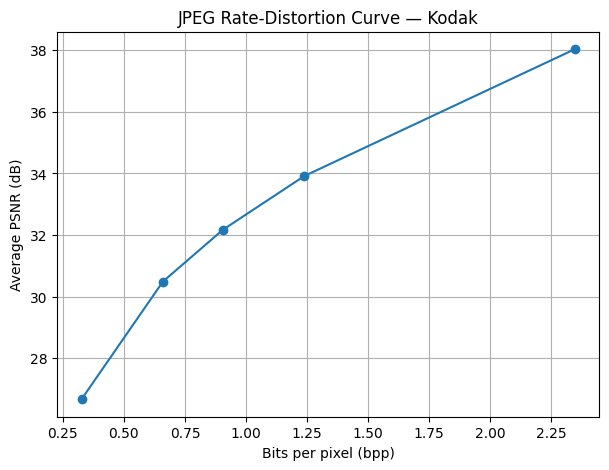

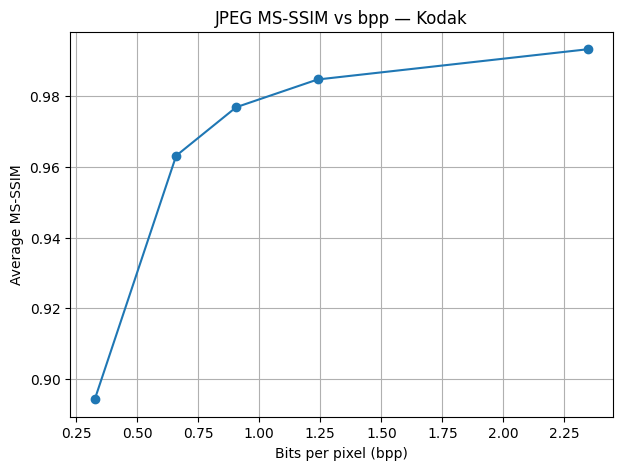

In [11]:

from pathlib import Path
from io import BytesIO
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

dataset_dir = Path("/content/kodak")
output_dir = Path("/content/jpeg_evaluation")
output_dir.mkdir(parents=True, exist_ok=True)

quality_levels = [10, 30, 50, 70, 90]
decode_repeats = 10

image_paths = sorted(dataset_dir.glob("kodim*.png"))

assert len(image_paths) == 24, (
    f"Expected 24 Kodak images, found {len(image_paths)}"
)

results = []

for image_path in image_paths:
    with Image.open(image_path) as img:
        original = img.convert("RGB")

    width, height = original.size

    for quality in quality_levels:
        compressed_path = (
            output_dir / f"{image_path.stem}_q{quality}.jpg"
        )

        # Encode JPEG
        original.save(
            compressed_path,
            format="JPEG",
            quality=quality
        )

        # Actual compressed file size
        compressed_bytes = compressed_path.read_bytes()
        file_size = len(compressed_bytes)

        bpp = calculate_bpp(file_size, width, height)

        # Decode once for quality evaluation
        with Image.open(BytesIO(compressed_bytes)) as decoded:
            reconstructed = decoded.convert("RGB")

        psnr = calculate_psnr(original, reconstructed)
        msssim_score = calculate_ms_ssim(
            original, reconstructed
        )

        # Measure repeated in-memory decoding.
        # File reading is excluded from the timed section.
        decode_times_ms = []

        for _ in range(decode_repeats):
            start = perf_counter()

            with Image.open(BytesIO(compressed_bytes)) as decoded:
                decoded.load()

            elapsed_ms = (perf_counter() - start) * 1000
            decode_times_ms.append(elapsed_ms)

        results.append({
            "image": image_path.name,
            "quality": quality,
            "file_size_bytes": file_size,
            "bpp": bpp,
            "psnr_db": psnr,
            "ms_ssim": msssim_score,
            "decode_time_ms": np.median(decode_times_ms)
        })

    print(f"Finished: {image_path.name}")

# Save all individual results
df = pd.DataFrame(results)

csv_path = output_dir / "jpeg_all_images.csv"
df.to_csv(csv_path, index=False)

# Average results across all 24 images
summary = (
    df.groupby("quality")
      .agg(
          avg_bpp=("bpp", "mean"),
          avg_psnr_db=("psnr_db", "mean"),
          avg_ms_ssim=("ms_ssim", "mean"),
          avg_decode_ms=("decode_time_ms", "mean"),
          avg_file_size_bytes=("file_size_bytes", "mean")
      )
      .reset_index()
)

summary_path = output_dir / "jpeg_summary.csv"
summary.to_csv(summary_path, index=False)

print("\n===== JPEG SUMMARY: 24 KODAK IMAGES =====")
display(summary.round(4))

print("Detailed results:", csv_path)
print("Summary results:", summary_path)

# Plot 1: PSNR vs bpp
plt.figure(figsize=(7, 5))
plt.plot(
    summary["avg_bpp"],
    summary["avg_psnr_db"],
    marker="o"
)
plt.xlabel("Bits per pixel (bpp)")
plt.ylabel("Average PSNR (dB)")
plt.title("JPEG Rate-Distortion Curve — Kodak")
plt.grid(True)
plt.savefig(
    output_dir / "jpeg_psnr_bpp.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# Plot 2: MS-SSIM vs bpp
plt.figure(figsize=(7, 5))
plt.plot(
    summary["avg_bpp"],
    summary["avg_ms_ssim"],
    marker="o"
)
plt.xlabel("Bits per pixel (bpp)")
plt.ylabel("Average MS-SSIM")
plt.title("JPEG MS-SSIM vs bpp — Kodak")
plt.grid(True)
plt.savefig(
    output_dir / "jpeg_msssim_bpp.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()


## 8. Package the evaluation outputs

This final cell creates a ZIP archive containing the files inside `/content/jpeg_evaluation`.

- `shutil.make_archive` creates `jpeg_baseline_results.zip`.
- `root_dir=output_dir` means the archive contains the evaluation folder's contents (the CSV files and plots), rather than the entire Colab filesystem.
- `FileLink` displays a clickable link in the notebook output so the ZIP can be downloaded from Colab.

Run this after the full evaluation cell has completed successfully. If the evaluation folder is empty or incomplete, the ZIP will also be incomplete. Keep a copy outside the temporary Colab runtime if you need the results later.

In [12]:

from pathlib import Path
import shutil
from IPython.display import display, FileLink

output_dir = Path("/content/jpeg_evaluation")
zip_path = shutil.make_archive(
    "/content/jpeg_baseline_results",
    "zip",
    root_dir=output_dir
)

print("ZIP created:", zip_path)
display(FileLink(zip_path))


ZIP created: /content/jpeg_baseline_results.zip


/content/jpeg_baseline_results.zip